In [ ]:

%%capture

!pip install unsloth
# Also get the latest nightly Unsloth!
!pip uninstall unsloth -y && pip install --upgrade --no-cache-dir "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git

In [ ]:
from unsloth import FastLanguageModel
import torch
max_seq_length = 2048
dtype = None # None for auto detection. Float16 for Tesla T4, V100, Bfloat16 for Ampere+

load_in_4bit = True # Use 4bit quantization to reduce memory usage.

# Find all unsloth supported models here https://docs.unsloth.ai/get-started/all-our-models

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Llama-3.2-1B-Instruct",
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
    # token = "...", # hugging face token if needed
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2025.3.19: Fast Llama patching. Transformers: 4.50.3.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post3. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!



This code is applying LoRA (Low-Rank Adaptation) to the preloaded model using Unsloth's PEFT (Parameter-Efficient Fine-Tuning) method.⬇️⬇️

In [ ]:

# q_proj, k_proj, v_proj: Query, Key, Value projections in attention

# These handle how tokens interact with each other
# Critical for understanding relationships between words


# o_proj: Output projection from attention
# gate_proj, up_proj, down_proj: MLP layers

# Handle non-linear transformations
# Important for model's reasoning capacity


model = FastLanguageModel.get_peft_model(
    model,
    r = 16, # The rank dimention. Lower rank means Less memory usage ex. 8, 16, 32, 64, 128
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for very long context
    random_state = 3407,
    use_rslora = False,  # We support rank stabilized LoRA
    loftq_config = None, # And LoftQ
)

Unsloth 2025.3.19 patched 16 layers with 16 QKV layers, 16 O layers and 16 MLP layers.


This code prepares a dataset for fine-tuning the Llama-3.1 model using Unsloth and the Spider dataset from Hugging Face's datasets library.⬇️⬇️⬇️⬇️⬇️


In [ ]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(
    tokenizer,
    chat_template = "llama-3.1",
)

def format_entries(entry):
    # Format conversations as list of dictionaries with alternating user/assistant messages
    conversations = [
        [
            {"role": "user", "content": question},
            {"role": "assistant", "content": query}
        ]
        for question, query in zip(entry["question"], entry["query"])
    ]

    # Apply chat template to each conversation
    texts = [
        tokenizer.apply_chat_template(convo, tokenize=False, add_generation_prompt=False)
        for convo in conversations
    ]
    return {"text": texts}


from datasets import load_dataset
ds = load_dataset("xlangai/spider", split = "train")
dataset = ds.map(format_entries, batched = True,)


In [ ]:
from unsloth.chat_templates import standardize_sharegpt
# dataset = standardize_sharegpt(ds)
dataset = ds.map(format_entries, batched = True,)

In [ ]:
dataset[5]["text"]

"<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 26 July 2024\n\n<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nWhat are the names of the heads who are born outside the California state?<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\nSELECT name FROM head WHERE born_state != 'California'<|eot_id|>"

In [ ]:
from trl import SFTTrainer
from transformers import TrainingArguments, DataCollatorForSeq2Seq
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset,
    dataset_text_field = "text",
    max_seq_length = 2048,  # Increase if model supports it
    data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer),
    dataset_num_proc = 4,  # Use more workers for faster processing
    packing = False,
    args = TrainingArguments(
        per_device_train_batch_size = 16,  # Increased for stability
        gradient_accumulation_steps = 4,  # Effective batch size = 64
        warmup_steps = 1000,  # Smoother learning rate warmup
        num_train_epochs = 100,  # Long training for full convergence
        max_steps = -1,  # Train for full dataset
        learning_rate = 1e-4,  # Stable LR for long training
        max_grad_norm = 1.0,  # ✅ Correct,  # Prevent gradient explosions
        fp16 = False,  # Mixed precision for efficiency
        bf16 = True,  # BF16 is not needed for Colab GPUs
        logging_steps = 50,  # Log every 50 steps
        optim = "adamw_8bit",  # Efficient optimizer
        weight_decay = 0.02,  # Higher for long training stability
        lr_scheduler_type = "cosine_with_restarts",  # Smooth decay with resets
        seed = 3407,  # Reproducibility
        output_dir = "outputs",  # Save outputs here
        save_steps = 1000,  # Save every 1000 steps
        save_total_limit = 3,  # Keep last 3 checkpoints
        report_to = "none",  # No external logging
    ),
)


In [ ]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|start_header_id|>user<|end_header_id|>\n\n",
    response_part = "<|start_header_id|>assistant<|end_header_id|>\n\n",
)

In [ ]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs = 1
   \\   /|    Num examples = 7,000 | Num Epochs = 100
O^O/ \_/ \    Batch size per device = 16 | Gradient Accumulation steps = 4
\        /    Total batch size = 64 | Total steps = 10,900
 "-____-"     Number of trainable parameters = 11,272,192


Step,Training Loss
50,1.617200
100,1.251600
150,0.773900
200,0.677100
250,0.580100
300,0.524700
350,0.454800
400,0.387300
450,0.344700
500,0.287000


Step,Training Loss
50,1.617200
100,1.251600
150,0.773900
200,0.677100
250,0.580100
300,0.524700
350,0.454800
400,0.387300
450,0.344700
500,0.287000


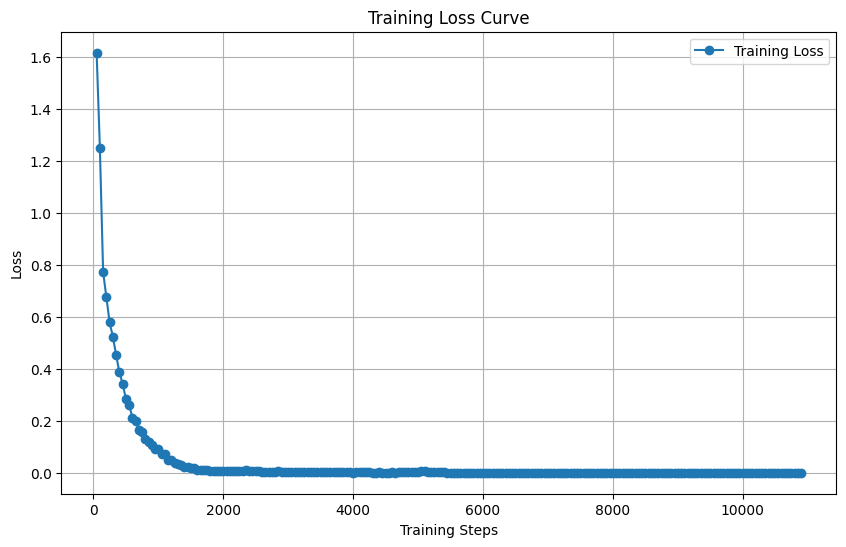

In [ ]:
import matplotlib.pyplot as plt

# Extract the training logs from the trainer
training_logs = trainer.state.log_history

# Extract the training steps and corresponding loss values
steps = [log["step"] for log in training_logs if "loss" in log]
loss_values = [log["loss"] for log in training_logs if "loss" in log]

# Plot the training loss
plt.figure(figsize=(10, 6))
plt.plot(steps, loss_values, label="Training Loss", marker='o')
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid()
plt.show()


In [ ]:
import torch

# Define the path where the model will be saved in Colab
COLAB_SAVE_PATH = "/content/QuerryVerse"

# Save model and tokenizer
model.save_pretrained(COLAB_SAVE_PATH)
tokenizer.save_pretrained(COLAB_SAVE_PATH)

print(f"Model saved in Colab at {COLAB_SAVE_PATH}")


Model saved in Colab at /content/QuerryVerse


In [ ]:
import os

# Check if the model folder exists
if os.path.exists(COLAB_SAVE_PATH):
    print("QuerryVerse model is saved in Colab!")
else:
    print("Error: Model not found!")


QuerryVerse model is saved in Colab!


In [ ]:
import shutil

# Zip the model folder
shutil.make_archive("/content/QuerryVerse", 'zip', "/content/QuerryVerse")

# Download the model
from google.colab import files
files.download("/content/QuerryVerse.zip")


In [ ]:
#started to use querryVerse
from transformers import AutoTokenizer
from unsloth import FastLanguageModel

# Define the saved path in Colab
COLAB_MODEL_PATH = "/content/QuerryVerse"

# Load the model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(COLAB_MODEL_PATH)
model, tokenizer = FastLanguageModel.from_pretrained(
    COLAB_MODEL_PATH,
    max_seq_length=2048,
    dtype=torch.float16
)

print("QuerryVerse model loaded successfully!")


==((====))==  Unsloth 2025.2.15: Fast Llama patching. Transformers: 4.48.3.
   \\   /|    GPU: NVIDIA A100-SXM4-40GB. Max memory: 39.557 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 8.0. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.29.post3. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
QuerryVerse model loaded successfully!


In [ ]:
!pip install mysql-connector-python


In [ ]:
#loading to huggingface
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
from huggingface_hub import HfApi

repo_name = "QueryVerse_final"  # Change if needed
username = "EvaruRaMeeruAntha"

api = HfApi()
api.create_repo(repo_name, private=False)  # Set private=True if you want it private

model.push_to_hub(f"{username}/{repo_name}")
tokenizer.push_to_hub(f"{username}/{repo_name}")


Saved model to https://huggingface.co/EvaruRaMeeruAntha/QueryVerse_final


Merged Model


In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel

# Define the base model and adapter from Hugging Face
base_model_name = "unsloth/Llama-3.2-1B-Instruct"
adapter_name = "EvaruRaMeeruAntha/QueryVerse_final"

# Load base model and tokenizer
model = AutoModelForCausalLM.from_pretrained(base_model_name, device_map="auto")
tokenizer = AutoTokenizer.from_pretrained(base_model_name)

# Load trained adapter into the base model
model = PeftModel.from_pretrained(model, adapter_name)

print("✅ Adapter loaded successfully!")


✅ Adapter loaded successfully!


In [ ]:
# Merge LoRA adapter with base model
model = model.merge_and_unload()

print("✅ Adapter merged successfully!")


✅ Adapter merged successfully!


Pushing to huggingface


In [ ]:
from huggingface_hub import HfApi, HfFolder

# Define local save path and Hugging Face repo
save_path = "merged_model"
repo_name = "QueryVerse_final_merged"
username = "EvaruRaMeeruAntha"

# Save the merged model and tokenizer locally
model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

# Authenticate using a secure API token

api_token = "<REDACTED>"  # 🔒 Replace with your new token securely
HfFolder.save_token(api_token)

# Initialize HfApi with token
api = HfApi(token=api_token)

# Create repo if it doesn't exist
api.create_repo(repo_id=f"{username}/{repo_name}", private=False, exist_ok=True)

# Push the merged model to Hugging Face
model.push_to_hub(f"{username}/{repo_name}", use_auth_token=True)
tokenizer.push_to_hub(f"{username}/{repo_name}", use_auth_token=True)

print(f"✅ Merged model pushed to Hugging Face: https://huggingface.co/{username}/{repo_name}")


/usr/local/lib/python3.11/dist-packages/transformers/utils/hub.py:894: FutureWarning: The `use_auth_token` argument is deprecated and will be removed in v5 of Transformers. Please use `token` instead.
  warnings.warn(


/usr/local/lib/python3.11/dist-packages/transformers/utils/hub.py:894: FutureWarning: The `use_auth_token` argument is deprecated and will be removed in v5 of Transformers. Please use `token` instead.
  warnings.warn(


✅ Merged model pushed to Hugging Face: https://huggingface.co/EvaruRaMeeruAntha/QueryVerse_final_merged


In [ ]:
from unsloth import FastLanguageModel
max_seq_length = 2048
dtype = None # None for auto detection. Float16 for Tesla T4, V100, Bfloat16 for Ampere+
load_in_4bit = True # Use 4bit quantization to reduce memory usage.
# Load the fine-tuned model from HuggingFace
hf_model, hf_tokenizer = FastLanguageModel.from_pretrained(
    model_name = "EvaruRaMeeruAntha/QueryVerse_final",
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
)

# Set up chat template
from unsloth.chat_templates import get_chat_template
hf_tokenizer = get_chat_template(
    hf_tokenizer,
    chat_template = "llama-3.1",
)

# Enable faster inference
FastLanguageModel.for_inference(hf_model)

# Function to generate response using the HF model
def get_hf_model_response(question):
    messages = [
        {"role": "user", "content": question},
    ]
    inputs = hf_tokenizer.apply_chat_template(
        messages,
        tokenize = True,
        add_generation_prompt = True,
        return_tensors = "pt"
    ).to("cuda")

    print(inputs)
    outputs = hf_model.generate(
        input_ids = inputs,
        max_new_tokens = 64,
        use_cache = True,
        temperature = 1.5,
        min_p = 0.1
    )
    return hf_tokenizer.batch_decode(outputs)[0]

# Example usage
question = "how many users in the users table?"
response = get_hf_model_response(question)
print("Question:", question)
print("Response:", response)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2025.2.15: Fast Llama patching. Transformers: 4.48.3.
   \\   /|    GPU: NVIDIA A100-SXM4-40GB. Max memory: 39.557 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 8.0. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.29.post3. FA2 = False]
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Unsloth 2025.2.15 patched 16 layers with 16 QKV layers, 16 O layers and 16 MLP layers.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


tensor([[128000, 128006,   9125, 128007,    271,  38766,   1303,  33025,   2696,
             25,   6790,    220,   2366,     18,    198,  15724,   2696,     25,
            220,   1627,   5887,    220,   2366,     19,    271, 128009, 128006,
            882, 128007,    271,   5269,   1690,   3932,    304,    279,   3932,
           2007,     30, 128009, 128006,  78191, 128007,    271]],
       device='cuda:0')
Question: how many users in the users table?
Response: <|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

<|eot_id|><|start_header_id|>user<|end_header_id|>

how many users in the users table?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

SELECT count(*) FROM users<|eot_id|>


In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

# Define model path from Hugging Face
model_name = "EvaruRaMeeruAntha/QueryVerse_final_merged"

# Load tokenizer and model from Hugging Face
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16, device_map="auto")

print("✅ Model loaded successfully!")


✅ Model loaded successfully!


In [ ]:
db_schema = """
TABLE employees (
    id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary INT
);

TABLE departments (
    id INT PRIMARY KEY,
    name VARCHAR(50)
);
"""


In [ ]:
question = "Get the names of employees who earn more than 50000."


In [ ]:
from transformers import AutoTokenizer
from unsloth import FastLanguageModel
import torch

# Define model path (from Hugging Face)
model_name = "EvaruRaMeeruAntha/QueryVerse_final_merged"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load model using Unsloth
max_seq_length = 2048  # This is what you mentioned during training
model = FastLanguageModel.from_pretrained(
    model_name,
    max_seq_length=max_seq_length,
    dtype=torch.float16,
    device_map="auto"
)

print("✅ Model loaded successfully!")


==((====))==  Unsloth 2025.3.19: Fast Llama patching. Transformers: 4.50.3.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post3. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


✅ Model loaded successfully!


In [ ]:
import torch
from transformers import AutoTokenizer
from unsloth import FastLanguageModel

# Load model from Hugging Face
model_name = "EvaruRaMeeruAntha/QueryVerse_final_merged"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load model correctly
model_tuple = FastLanguageModel.from_pretrained(
    model_name,
    max_seq_length=2048,
    dtype=torch.float16,
    device_map="auto"
)

model = model_tuple[0]  # Extract model from tuple

# **IMPORTANT: Enable inference mode**
FastLanguageModel.for_inference(model)

# Define schema and question
db_schema = """
TABLE employees (
    id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary INT
);

TABLE departments (
    id INT PRIMARY KEY,
    name VARCHAR(50)
);
"""

question = "Get the names of employees who earn more than 50000."

# Create input prompt
prompt = f"Schema:\n{db_schema}\n\nQuestion: {question}\nSQL Query:"

# Tokenize input correctly
inputs = tokenizer(prompt, return_tensors="pt", padding=True, truncation=True).to("cuda")

# Generate SQL query
with torch.no_grad():
    outputs = model.generate(**inputs, max_length=200)

# Decode output
sql_query = tokenizer.decode(outputs[0], skip_special_tokens=True)
print("\nGenerated SQL Query:\n", sql_query)


==((====))==  Unsloth 2025.3.19: Fast Llama patching. Transformers: 4.50.3.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post3. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!

Generated SQL Query:
 Schema:

TABLE employees (
    id INT PRIMARY KEY,
    name VARCHAR(100),
    department VARCHAR(50),
    salary INT
);

TABLE departments (
    id INT PRIMARY KEY,
    name VARCHAR(50)
);


Question: Get the names of employees who earn more than 50000.
SQL Query: SELECT name FROM employees WHERE salary  >  50000;


In [ ]:
!pip install torch transformers unsloth aisuite accelerate bitsandbytes


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.4/76.4 kB 5.4 MB/s eta 0:00:00
  Attempting uninstall: httpx
    Found existing installation: httpx 0.28.1
    Uninstalling httpx-0.28.1:
      Successfully uninstalled httpx-0.28.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 1.9.0 requires httpx<1.0.0,>=0.28.1, but you have httpx 0.27.2 which is incompatible.


In [ ]:
!pip install gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 MB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.2/322.2 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 6.0 MB/s eta 0:00:00


In [ ]:
import torch
from transformers import AutoTokenizer
from unsloth import FastLanguageModel
import gradio as gr

# Load model from Hugging Face
model_name = "EvaruRaMeeruAntha/QueryVerse_final_merged"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load model using Unsloth
model_tuple = FastLanguageModel.from_pretrained(
    model_name,
    max_seq_length=2048,
    dtype=torch.float16,
    device_map="auto"
)
model = model_tuple[0]
FastLanguageModel.for_inference(model)

# Generate SQL function with improved prompting and output cleaning
def generate_sql(schema, question):
    # Clean schema: remove blank lines and extra spaces
    schema_cleaned = "\n".join(line.strip() for line in schema.strip().splitlines() if line.strip())

    # Prompt with instruction to keep output clean
    prompt = (
        "You are a SQL generator AI. You will be given a database schema and a natural language question.\n"
        "Generate only the SQL query without any explanation or formatting.\n\n"
        f"Schema:\n{schema_cleaned}\n\n"
        f"Question:\n{question.strip()}\n\n"
        "SQL:"
    )

    # Tokenize and move to GPU
    inputs = tokenizer(prompt, return_tensors="pt", padding=True, truncation=True).to("cuda")

    # Generate SQL
    with torch.no_grad():
        outputs = model.generate(**inputs, max_length=200)

    # Decode and clean output
    result = tokenizer.decode(outputs[0], skip_special_tokens=True)

    # Extract just the SQL (remove leading prompt if it appears)
    if "SQL:" in result:
        result = result.split("SQL:")[-1]

    result = result.strip().split("```")[0]  # remove markdown formatting if any
    return result.strip()

# Gradio UI
with gr.Blocks() as demo:
    gr.Markdown("## 🧠 Text-to-SQL Generator (Unsloth + Gradio)")

    with gr.Row():
        schema_input = gr.Textbox(
            label="📦 Database Schema",
            lines=10,
            placeholder="e.g. Customers(CustomerID, FirstName, LastName, Email, CreatedAt)\nOrders(OrderID, CustomerID, OrderDate)"
        )
        question_input = gr.Textbox(
            label="❓ Natural Language Question",
            placeholder="e.g. Show all customers who placed an order in the last 30 days."
        )

    generate_btn = gr.Button("🚀 Generate SQL")
    output_sql = gr.Textbox(label="🧾 Generated SQL Query", lines=5)

    generate_btn.click(fn=generate_sql, inputs=[schema_input, question_input], outputs=output_sql)

# Launch the Gradio interface
demo.launch(share=True)


==((====))==  Unsloth 2025.3.19: Fast Llama patching. Transformers: 4.50.3.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.741 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.6.0+cu124. CUDA: 7.5. CUDA Toolkit: 12.4. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.29.post3. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2e0a9a9c8ae3fd3ba5.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(128256, 2048, padding_idx=128004)
    (layers): ModuleList(
      (0-15): 16 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear4bit(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear4bit(in_features=2048, out_features=512, bias=False)
          (v_proj): Linear4bit(in_features=2048, out_features=512, bias=False)
          (o_proj): Linear4bit(in_features=2048, out_features=2048, bias=False)
          (rotary_emb): LlamaRotaryEmbedding()
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear4bit(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear4bit(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear4bit(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((

In [ ]:
!pip install rouge-score nltk

  Preparing metadata (setup.py) ... done
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=b1b0c37c8e04108c92d71e642ca6ec0d3d962633ba2c50b601428d2280bddfcc
  Stored in directory: /root/.cache/pip/wheels/1e/19/43/8a442dc83660ca25e163e1bd1f89919284ab0d0c1475475148
Successfully built rouge-score


In [ ]:
from huggingface_hub import login

# Use your provided API key
login("<REDACTED>")


In [ ]:
!pip install rouge
from nltk.translate.bleu_score import sentence_bleu
from rouge import Rouge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Define SQL Input Schema
sql_schema = """
CREATE TABLE Employees (
    EmployeeID INT PRIMARY KEY,
    Name VARCHAR(100),
    Age INT,
    Department VARCHAR(50),
    Salary DECIMAL(10,2),
    JoiningDate DATE
);

CREATE TABLE Departments (
    DepartmentID INT PRIMARY KEY,
    DepartmentName VARCHAR(50),
    ManagerID INT
);
"""

# Define SQL Question
sql_question = "Write an SQL query to find the average salary of employees in each department, ordered from highest to lowest."

# Expected Correct SQL Output
expected_sql_output = """
SELECT Department, AVG(Salary) AS AvgSalary
FROM Employees
GROUP BY Department
ORDER BY AvgSalary DESC;
"""

# Function to compute evaluation metrics
def evaluate_response(model_name, generated_sql, expected_sql):
    rouge = Rouge()

    # BLEU Score
    bleu_score = sentence_bleu([expected_sql.split()], generated_sql.split())

    # ROUGE Score
    rouge_scores = rouge.get_scores(generated_sql, expected_sql)[0]

    # Cosine Similarity (TF-IDF)
    vectorizer = TfidfVectorizer()
    vectors = vectorizer.fit_transform([generated_sql, expected_sql])
    cosine_sim = cosine_similarity(vectors)[0, 1]

    # Print Evaluation Results
    print(f"\n=== {model_name} ===")
    print("Generated SQL:\n", generated_sql)
    print("\nEvaluation Metrics:")
    print(f"BLEU Score: {bleu_score:.4f}")
    print(f"ROUGE Scores: {rouge_scores}")
    print(f"Cosine Similarity: {cosine_sim:.4f}")
    print("-" * 50)

# Generate responses from each model
response_mistral = generate_response(mistral_model, mistral_tokenizer, sql_question)
response_queryverse = generate_response(queryverse_model, queryverse_tokenizer, sql_question)

# Evaluate each model
evaluate_response("Mistral-7B", response_mistral, expected_sql_output)
evaluate_response("QueryVerse Fine-Tuned", response_queryverse, expected_sql_output)
